**Pandas** is one of the most widely used Python libraries for **data analysis and manipulation.** It is open-source and built on top of **NumPy.** It adds high-level data structures and tools that make it easier to work with **tabular, labeled,** or **heterogeneous** datasets.

**Data Structures**
Pandas introduces two important data structures: **Series** & **DataFrame.**


In [1]:
#Usage 
dict_a = {"name":["Alice","Bob","Charlie"], "age":[25,30,35], "city":["New York","Los Angeles","Chicago"]}

import pandas as pd
df = pd.DataFrame(dict_a)

df

,name,age,city
0,Alice,25,New York
1,Bob,30,Los Angeles
2,Charlie,35,Chicago


## Series
A Series is a **one-dimensional labeled array** (like a column in a spreadsheet). It can hold data of any type: integers, floats, strings, Python objects.

It has two main components:
1. **Values** - the actual data
2. **Index** - labels for each value


In [2]:
#Usage
s = pd.Series([1, 2, 3, 4, 5])
print(s)    
print(type(s))

0    1
1    2
2    3
3    4
4    5
dtype: int64
<class 'pandas.core.series.Series'>


In [3]:
#Indexing 
print(s[0])  # Accessing the first element
print(s[:3])  # Accessing the first three elements
print(s[s > 2])  # Accessing elements greater than 2
print(s[[0, 2, 4]])  # Accessing specific elements by index
print(s.index)  # Accessing the index of the Series

#Custom Indexing
s_custom = pd.Series([23,24,28,32], index=["Alice","Bob","Charlie","David"])
print(s_custom.index)
print(s_custom[1])  # Accessing the second element using default index
print(s_custom["Bob"])  # Accessing the element with custom index "Bob"
print(s_custom[:2])  # Accessing the first two elements using default index
print(s_custom[["Alice","David"]])  # Accessing elements with custom indices "Alice" and "David"

#Vectorized Operations
s1 = pd.Series([1, 2, 3, 4, 5])
s2 = pd.Series([10, 20, 30, 40, 50])
print(s1 + s2)  # Element-wise addition
print(s1 * 2)  # Scalar multiplication

#Mutable values but immutable size
s = pd.Series([1, 2, 3, 4, 5])
s[0] = 10  # Modifying the first element
print(s)

changed_s = s.drop(1)  # Dropping the element at index 1
print(changed_s)  # The original Series remains unchanged
print(s)  # The original Series remains unchanged

#Handling Missing Values
s= pd.Series([1, 2, 3, 4, None])
print(s[s.isna()])  # Checking for missing values

print(s.dropna())  # Dropping missing values
print(s.fillna(0))  # Filling missing values with 0

1
0    1
1    2
2    3
dtype: int64
2    3
3    4
4    5
dtype: int64
0    1
2    3
4    5
dtype: int64
RangeIndex(start=0, stop=5, step=1)
Index(['Alice', 'Bob', 'Charlie', 'David'], dtype='object')
24
24
Alice    23
Bob      24
dtype: int64
Alice    23
David    32
dtype: int64
0    11
1    22
2    33
3    44
4    55
dtype: int64
0     2
1     4
2     6
3     8
4    10
dtype: int64
0    10
1     2
2     3
3     4
4     5
dtype: int64
0    10
2     3
3     4
4     5
dtype: int64
0    10
1     2
2     3
3     4
4     5
dtype: int64
4   NaN
dtype: float64
0    1.0
1    2.0
2    3.0
3    4.0
dtype: float64
0    1.0
1    2.0
2    3.0
3    4.0
4    0.0
dtype: float64


/tmp/ipykernel_606936/3398613298.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(s_custom[1])  # Accessing the second element using default index


In [4]:
#Reset index
s = pd.Series([1, 2, 3, 4, 5], index=['a', 'b', 'c', 'd', 'e'])
print(s.index)
# print(s['index'])  # This will raise an error because 'index' is not a valid index label
s_rest_1 = s.reset_index()  # Resetting the index and creates a new DataFrame with the old index as a column
print(s_rest_1)  # The new DataFrame with the old index as a column
print(s_rest_1.index)
print(s_rest_1['index']) # Accessing the old index column

#Reset index with drop
s_rest_2 = s.reset_index(drop=True)  # Resetting the index and dropping the old index
print(s_rest_2)  # The new Series with a default integer index
print(s_rest_2.index)  # The new default integer index

Index(['a', 'b', 'c', 'd', 'e'], dtype='object')
  index  0
0     a  1
1     b  2
2     c  3
3     d  4
4     e  5
RangeIndex(start=0, stop=5, step=1)
0    a
1    b
2    c
3    d
4    e
Name: index, dtype: object
0    1
1    2
2    3
3    4
4    5
dtype: int64
RangeIndex(start=0, stop=5, step=1)


### Characteristics of a Series
1. **Homogeneous data:** All elements in a Series must be of the same data type (e.g., all integers, all floats, all strings).
2. **Vectorized operations:** Series support element-wise operations, allowing for efficient mathematical computations.
3. **Mutable values but immutable size:** You can change the values of a Series, but you cannot change its size.
4. **Missing values:** Series can handle missing values (NaN) and provide methods to handle them.

In [5]:
import numpy as np
arr = np.array([[1, 2, 3], [4, 5, 6]])
arr.sum(axis=1)

array([ 6, 15])

## Dataframe
DataFrame is a two-dimensional labeled data structure with columns of potentially different types. It is similar to a spreadsheet or SQL table, or a dictionary of Series objects. You can think of it as a collection of Series objects that share the same index.

In [6]:
#Different ways of creating dataframe
#From a dictionary of lists
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, 35],
    'City': ['New York', 'Los Angeles', 'Chicago']
}
df1 = pd.DataFrame(data)
print(df1,type(df1))

#Rows labels
print(df1.index)

#From list of lists
data = [
    ['Alice', 25, 'New York'],
    ['Bob', 30, 'Los Angeles'],
    ['Charlie', 35, 'Chicago']
]
df2 = pd.DataFrame(data, columns=['Name', 'Age', 'City'],index=['row1', 'row2', 'row3'])
print(df2,type(df2))

#Rows labels
print(df2.index)

#From Numpy arrays
arr = np.array([[1, 2, 3], [4, 5, 6]])
df3 = pd.DataFrame(arr, columns=['A', 'B', 'C'],index=['row1', 'row2'])
print(df3,type(df3))
print(df3.index)

    

      Name  Age         City
0    Alice   25     New York
1      Bob   30  Los Angeles
2  Charlie   35      Chicago <class 'pandas.core.frame.DataFrame'>
RangeIndex(start=0, stop=3, step=1)
         Name  Age         City
row1    Alice   25     New York
row2      Bob   30  Los Angeles
row3  Charlie   35      Chicago <class 'pandas.core.frame.DataFrame'>
Index(['row1', 'row2', 'row3'], dtype='object')
      A  B  C
row1  1  2  3
row2  4  5  6 <class 'pandas.core.frame.DataFrame'>
Index(['row1', 'row2'], dtype='object')


In [7]:
#Create a dataframe with file data

#creating a dataframe from a CSV file
df4 = pd.read_csv('./employee_data.csv')
print(df4,type(df4))
print(df4.index)

   ID     Name  Age Department  Salary
0   1    Alice   25         HR   55000
1   2      Bob   32         IT   72000
2   3  Charlie   28    Finance   48000
3   4    David   45  Marketing   91000
4   5      Eva   38         IT   65000
5   6    Frank   29    Finance   50000
6   7    Grace   41         HR   82000
7   8   Hannah   26  Marketing   47000
8   9      Ian   35         IT   75000
9  10    Julia   30    Finance   60000 <class 'pandas.core.frame.DataFrame'>
RangeIndex(start=0, stop=10, step=1)


In [8]:
#Creating the dataframe with JSON data
df5 = pd.read_json('./employee_data.json')
print(df5,type(df5))    

   ID     Name  Age Department  Salary
0   1    Alice   25         HR   55000
1   2      Bob   32         IT   72000
2   3  Charlie   28    Finance   48000
3   4    David   45  Marketing   91000
4   5      Eva   38         IT   65000
5   6    Frank   29    Finance   50000
6   7    Grace   41         HR   82000
7   8   Hannah   26  Marketing   47000
8   9      Ian   35         IT   75000
9  10    Julia   30    Finance   60000 <class 'pandas.core.frame.DataFrame'>


### DataFrame Methods
- head() : Returns the first n rows of the DataFrame (default is 5)
- tail() : Returns the last n rows of the DataFrame (default is 5)
- random() : Returns a random sample of n rows from the DataFrame
- shape : Returns a tuple representing the dimensionality of the DataFrame (number of rows, number of columns)
- describe() : Generates descriptive statistics of the DataFrame, including count, mean, standard deviation, minimum, maximum, and quartile values for numerical columns
- columns : Returns the column labels of the DataFrame
- nunique() - Returns the number of unique values in each column of the DataFrame





In [9]:
#Methods
#head() - Returns the first n rows of the DataFrame (default is 5)
print(df4.head())  # Returns the first 5 rows
print(df4.head(2))  # Returns the first 2 rows

#tail() - Returns the last n rows of the DataFrame (default is 5)
print(df4.tail())  # Returns the last 5 rows    
print(df4.tail(2))  # Returns the last 2 rows

#random() - Returns a random sample of n rows from the DataFrame
print(df4.sample(n=2))  # Returns a random sample of 2 rows

#info() - Provides a concise summary of the DataFrame, including the number of non-null entries, data types, and memory usage
print(df4.info())  # Provides a concise summary of the DataFrame

#shape - Returns a tuple representing the dimensionality of the DataFrame (number of rows, number of columns)
print(df4.shape)  # Returns the shape of the DataFrame

#describe() - Generates descriptive statistics of the DataFrame, including count, mean, standard deviation, minimum, maximum, and quartile values for numerical columns
print(df4.describe())  # Generates descriptive statistics of the DataFrame

#columns - Returns the column labels of the DataFrame
print(df4.columns)  # Returns the column labels of the DataFrame

#nunique() - Returns the number of unique values in each column of the DataFrame
print(df4.nunique())  # Returns the number of unique values in each column of the

   ID     Name  Age Department  Salary
0   1    Alice   25         HR   55000
1   2      Bob   32         IT   72000
2   3  Charlie   28    Finance   48000
3   4    David   45  Marketing   91000
4   5      Eva   38         IT   65000
   ID   Name  Age Department  Salary
0   1  Alice   25         HR   55000
1   2    Bob   32         IT   72000
   ID    Name  Age Department  Salary
5   6   Frank   29    Finance   50000
6   7   Grace   41         HR   82000
7   8  Hannah   26  Marketing   47000
8   9     Ian   35         IT   75000
9  10   Julia   30    Finance   60000
   ID   Name  Age Department  Salary
8   9    Ian   35         IT   75000
9  10  Julia   30    Finance   60000
   ID   Name  Age Department  Salary
5   6  Frank   29    Finance   50000
3   4  David   45  Marketing   91000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ID          10 non-

In [10]:
#AQI data
df = pd.read_csv("/home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/pandas/globalAirQuality.csv")

df.head()
df.tail()
df.describe()

,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
count,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000
mean,23.065980,37.655560,40.369131,70.152228,32.055176,6.035508,48.065100,0.800595,104.645556,21.510251,57.714351,5.283910
std,26.156536,78.600701,17.647450,24.999440,13.820680,2.454790,14.950849,0.250254,25.616070,9.509444,18.844908,2.741712
min,-37.814000,-123.121000,0.025000,0.061000,0.013000,0.003000,0.114000,0.000000,16.000000,5.000000,25.002000,0.500000
25%,12.972000,2.352000,27.904500,53.125500,22.362500,4.360750,38.028500,0.633000,87.000000,13.357750,41.320000,2.937000
50%,29.232000,42.146000,40.286500,69.961000,32.019500,6.026000,48.142000,0.800500,103.000000,21.455500,57.847000,5.297000
75%,41.008000,103.820000,52.436250,87.256500,41.364250,7.715250,58.258500,0.969000,121.000000,29.688250,74.234750,7.662000
max,60.170000,174.763000,115.683000,161.810000,90.019000,16.559000,103.016000,1.832000,231.000000,37.998000,89.997000,9.999000


In [11]:
df.head()

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017


### Selecting Data

In [12]:
# Selecting specific columns
df["city"]  # Selecting the "city" column
df[["city", "aqi"]]  # Selecting multiple columns "city" and "aqi"

,city,aqi
0,New York,108
1,New York,90
2,New York,84
3,New York,158
4,New York,97
...,...,...
17995,Zurich,103
17996,Zurich,105
17997,Zurich,122
17998,Zurich,95


In [13]:
df.head()

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017


In [14]:
#Select rows
#loc
df.loc[2]  # Selecting the third row by index label
df.loc[2:5]  # Selecting rows from index label 2 to 4 (inclusive of 2, inclusive of 5)

#iloc
df.iloc[0]  # Selecting the first row by integer position
df.iloc[0:3]  # Selecting the first three rows by integer position (inclusive of 0, exclusive of 3)

#cells - row, col
df.loc[0, "city"]  # Selecting the value in the first row and "city" column by index label
df.loc[0:3, ["city", "aqi"]]  # Selecting the values in the first four rows and "city" and "aqi" columns by index label

# df.iloc[0,"city"] #Selecting the row by string index will give error. It should be integer index
df.iloc[0, 2]  # Selecting the value in the first row and second column by integer position
df.iloc[0:3, [2,11]]  # Selecting the values in the first three rows and second and third columns by integer position

df.loc[0:2, ["country","city","latitude","longitude"]]  # Selecting specific columns for the first four rows by index label
df.iloc[0:3, 1:5]  # Selecting specific columns for the first three rows by integer position

#selecting cells by at,iat
df.at[0, "city"]  # Selecting the value in the first row and "city" column by index label
df.iat[0, 2]  # Selecting the value in the first row and second column by integer position


# Slicing is view in pandas, so changes made to the sliced DataFrame will affect the original DataFrame. To avoid this, you can create a copy of the sliced DataFrame using the copy() method.
cities = df["city"]
cities[0] = "New City"  # Modifying the first element of the sliced Series

cities = df["city"].copy()  # Creating a copy of the sliced Series
cities[0] = "Mumbai"  # Modifying the first element of the sliced Series




/tmp/ipykernel_606936/2375221737.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cities[0] = "New City"  # Modifying the first element of the sliced Series


In [15]:
df.head(10)  # Returns the first 10 rows

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New City,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017
5,2025-11-04 23:25:17.554219,US,New York,40.713,-74.006,31.242,92.779,30.633,8.030,43.725,0.347,92,15.159,42.505,1.199
6,2025-11-05 00:25:17.554219,US,New York,40.713,-74.006,77.690,65.198,20.302,7.641,62.687,0.734,155,36.729,47.651,4.542
7,2025-11-05 01:25:17.554219,US,New York,40.713,-74.006,57.816,111.709,34.533,6.945,41.304,0.771,115,37.891,53.314,7.605
8,2025-11-05 02:25:17.554219,US,New York,40.713,-74.006,60.914,44.775,40.936,6.779,36.751,1.014,121,24.092,48.148,8.686
9,2025-11-05 03:25:17.554219,US,New York,40.713,-74.006,16.464,76.631,28.119,8.561,79.467,1.081,76,11.490,29.403,3.762


### FilteringData

In [16]:
df[df["aqi"] > 100]  # Filtering rows where the "aqi" column is greater than 100
df[(df["aqi"] > 100) & (df["temperature"] > 30)]  # Filtering rows where the "aqi" column is greater than 100 and the temperature is greater than 30
df[(df["aqi"] > 100) & (df["temperature"] < 30)]  # Filtering rows where the "aqi" column is greater than 100 and the temperature is less than 30
aqi_data = df[(df["aqi"] > 100) & (df["temperature"] > 30)][["aqi","city"]]  
aqi_data
aqi_data.index

Index([    6,     7,    14,    17,    25,    29,    31,    35,    38,    44,
       ...
       17911, 17920, 17928, 17932, 17940, 17947, 17950, 17975, 17976, 17991],
      dtype='int64', length=2384)

In [17]:
aqi_data.iloc[0]  # Selecting the first row of the filtered DataFrame
# aqi_data.loc[0]  # Gives error because the index of the filtered DataFrame is not reset, so there is no row with index label 0. To access the first row, you can use iloc[0] or reset the index of the filtered DataFrame using reset_index() method.
aqi_data.loc[6]
aqi_data
aqi_data.reset_index(drop=True, inplace=True)  # Resetting the index of the filtered DataFrame and dropping the old index
aqi_data.loc[0]  # Now you can access the first row using loc[0] after resetting the index

aqi          155
city    New York
Name: 0, dtype: object

### Filtering data by query() rules:
- Expression as a string : Ex: "aqi > 100 and temperature > 30"
- Column based reference.
- Backticks for column names with spaces or special characters.
- Operators (&, |, ~, >, <, >=, <=, ==, !=) for logical operations.
- @ to refernce Python variables within the query string.
- Chained comparisons: Ex: "30 < temperature < 40"

In [18]:
df.query("aqi > 100")
df.query("aqi > 100 & temperature > 30")[["aqi","city"]]
aqi_val = 100
df.query("aqi > @aqi_val")  # Using a variable in the query method
df.query("30 < temperature < 40")  # Chained comparison
# Query always returns a copy of the DataFrame, so changes made to the queried DataFrame will not affect the original DataFrame. To avoid this, you can use the inplace parameter in the query method to modify the original DataFrame directly.

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
6,2025-11-05 00:25:17.554219,US,New York,40.713,-74.006,77.690,65.198,20.302,7.641,62.687,0.734,155,36.729,47.651,4.542
7,2025-11-05 01:25:17.554219,US,New York,40.713,-74.006,57.816,111.709,34.533,6.945,41.304,0.771,115,37.891,53.314,7.605
14,2025-11-05 08:25:17.554219,US,New York,40.713,-74.006,38.815,121.394,25.969,4.112,44.730,1.124,121,34.481,81.790,3.576
17,2025-11-05 11:25:17.554219,US,New York,40.713,-74.006,63.552,57.838,13.754,4.427,42.251,0.997,127,36.193,62.906,7.097
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17979,2025-11-18 21:25:17.554219,CH,Zurich,47.377,8.542,23.366,53.536,22.666,5.740,36.770,0.894,56,34.984,71.501,8.024
17983,2025-11-19 01:25:17.554219,CH,Zurich,47.377,8.542,21.900,84.621,28.605,8.958,53.178,0.621,84,35.020,71.804,8.901
17990,2025-11-19 08:25:17.554219,CH,Zurich,47.377,8.542,29.621,27.051,13.218,9.936,49.502,0.678,59,32.144,67.180,6.809
17991,2025-11-19 09:25:17.554219,CH,Zurich,47.377,8.542,52.120,71.160,35.405,7.752,39.811,0.878,104,32.556,31.372,2.787


## Cleaning the data
- Handle Missing Values
- Handle Duplicates
- Handling diff datatypes
- Handling Strings

### Handle Missing Values
- isnull/isna() - Returns a boolean Series indicating whether each element is missing (NaN) or not
- isnull().sum() - Returns the number of missing values in each column
- dropna() - Returns a new DataFrame with missing values removed
- fillna(value) - Returns a new DataFrame with missing values filled with the specified value
- ffill() - Returns a new DataFrame with missing values forward filled (propagating the last valid observation forward)
- bfill() - Returns a new DataFrame with missing values backward filled (propagating the next valid observation backward)

In [19]:
df = pd.read_csv("/home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/pandas/raw_data.csv") # Loading a CSV file into a DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       11 non-null     int64  
 1   name     10 non-null     object 
 2   age      8 non-null      float64
 3   country  10 non-null     object 
 4   gender   10 non-null     object 
 5   income   10 non-null     float64
dtypes: float64(2), int64(1), object(3)
memory usage: 656.0+ bytes


In [20]:
df.isnull().sum()  # Checking for missing values in each column

id         0
name       1
age        3
country    1
gender     1
income     1
dtype: int64

In [21]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [22]:
df.isnull()

,id,name,age,country,gender,income
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,True,False,False,False
4,False,False,False,False,False,True
5,False,False,False,False,False,False
6,False,True,False,False,False,False
7,False,False,False,True,False,False
8,False,False,False,False,False,False
9,False,False,True,False,False,False


In [23]:
df.isna()

,id,name,age,country,gender,income
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,True,False,False,False
4,False,False,False,False,False,True
5,False,False,False,False,False,False
6,False,True,False,False,False,False
7,False,False,False,True,False,False
8,False,False,False,False,False,False
9,False,False,True,False,False,False


In [24]:
df.dropna()

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
5,5,Li Wei,27.0,China,Male,51000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0


In [25]:
df.dropna(axis=0)  # Dropping rows with missing values
df.dropna(axis=1)  # Dropping columns with missing values

,id
0,1
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [26]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [27]:
df.fillna(0)  # Filling missing values with 0
df.fillna(100)  # Filling missing values with 0
df["age"].fillna(df["age"].mean())  # Filling missing values in the "age" column with the mean value

0     29.00
1     29.00
2     32.75
3     32.75
4     34.00
5     27.00
6     45.00
7     38.00
8     29.00
9     32.75
10    31.00
Name: age, dtype: float64

In [28]:
cleaned_data = df.copy()  # Creating a copy of the DataFrame to avoid modifying the original DataFrame
cleaned_data["age"].fillna(cleaned_data["age"].mean(), inplace=True)  # Filling missing values in the "age" column with the mean value and modifying the original DataFrame
cleaned_data

/tmp/ipykernel_606936/2017717666.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  cleaned_data["age"].fillna(cleaned_data["age"].mean(), inplace=True)  # Filling missing values in the "age" column with the mean value and modifying the original DataFrame


,id,name,age,country,gender,income
0,1,John Doe,29.00,USA,Male,55000.0
1,1,John Doe,29.00,USA,Male,55000.0
2,2,Jane Smith,32.75,Canada,Female,62000.0
3,3,Alex,32.75,USA,Unknown,47000.0
4,4,Maria Garcia,34.00,Spain,Female,NaN
5,5,Li Wei,27.00,China,Male,51000.0
6,6,NaN,45.00,India,Female,73000.0
7,7,Ahmed Khan,38.00,NaN,Male,68000.0
8,8,Rachel Lee,29.00,USA,Female,62000.0
9,9,Carlos Ruiz,32.75,Mexico,Male,45000.0


In [29]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [30]:
df["age"].ffill()  # Forward filling missing values in the "age" column

0     29.0
1     29.0
2     29.0
3     29.0
4     34.0
5     27.0
6     45.0
7     38.0
8     29.0
9     29.0
10    31.0
Name: age, dtype: float64

In [31]:
df.ffill()  # Forward filling missing values in the entire DataFrame

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,29.0,Canada,Female,62000.0
3,3,Alex,29.0,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,47000.0
5,5,Li Wei,27.0,China,Male,51000.0
6,6,Li Wei,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,India,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,29.0,Mexico,Male,45000.0


In [32]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [33]:
df.bfill()  # Backward filling missing values in the entire DataFrame

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,34.0,Canada,Female,62000.0
3,3,Alex,34.0,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,51000.0
5,5,Li Wei,27.0,China,Male,51000.0
6,6,Ahmed Khan,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,USA,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,31.0,Mexico,Male,45000.0


## Handle Duplicate Rows
- df.drop_duplicates()  # Remove duplicate rows from the DataFrame
- df.duplicated()  # Check for duplicate rows in the DataFrame
- Handling different datatypes.


In [34]:
df.duplicated()

0     False
1      True
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
dtype: bool

In [35]:
df[["country","gender"]].duplicated()  # Checking for duplicate values in the "country" and "gender" columns

0     False
1      True
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
dtype: bool

In [36]:
df.drop_duplicates()  # Dropping duplicate rows from the DataFrame

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0
10,10,Emily Davis,31.0,USA,NaN,58000.0


In [37]:
df[df.duplicated()]  # Displaying the duplicate rows in the DataFrame

,id,name,age,country,gender,income
1,1,John Doe,29.0,USA,Male,55000.0


In [38]:
df[df.duplicated(subset=["country"], keep=False) ] # Checking for duplicate values in the "country" column

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
3,3,Alex,NaN,USA,Unknown,47000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
10,10,Emily Davis,31.0,USA,NaN,58000.0


In [39]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


### Handling Data types : 
In pandas, data types are important for efficient memory usage and performance. You can check the data types of each column in a DataFrame using the `dtypes` attribute. You can also convert data types using the `astype()` method.
- dtypes - Returns the data types of each column in the DataFrame
- astype() - Converts the data type of a column to a specified data type
- to_datetime() - Converts a column to datetime data type - Ex: "2021-01-01" can be converted to datetime using pd.to_datetime("2021-01-01")

In [40]:
df.dtypes  # Checking the data types of each column in the DataFrame

id           int64
name        object
age        float64
country     object
gender      object
income     float64
dtype: object

In [41]:
df2 = df.copy()  # Creating a copy of the DataFrame to avoid modifying the original DataFrame
df2["age"] = df2["age"].fillna(df2["age"].mean())  # Filling missing values in the "age" column with the mean value and modifying the copied DataFrame
df2["age"] = df2["age"].astype("int64")  # Converting the "age" column to integer data type
df2["age"]

0     29
1     29
2     32
3     32
4     34
5     27
6     45
7     38
8     29
9     32
10    31
Name: age, dtype: int64

In [42]:
df2["age"].dtype  # Checking the data type of the "age" column in the copied DataFrame

dtype('int64')

In [43]:
aqi_data = pd.read_csv("/home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/pandas/globalAirQuality.csv")  # Loading a CSV file into a DataFrame

In [44]:
aqi_data

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17995,2025-11-19 13:25:17.554219,CH,Zurich,47.377,8.542,27.899,74.179,41.474,6.677,50.869,1.028,103,7.079,52.443,7.452
17996,2025-11-19 14:25:17.554219,CH,Zurich,47.377,8.542,2.950,47.988,42.235,2.821,35.551,0.644,105,28.734,85.678,4.496
17997,2025-11-19 15:25:17.554219,CH,Zurich,47.377,8.542,61.347,72.908,46.976,5.763,66.492,0.947,122,21.951,72.311,9.660
17998,2025-11-19 16:25:17.554219,CH,Zurich,47.377,8.542,40.722,95.152,32.957,5.524,53.193,0.868,95,24.042,31.880,2.642


In [45]:
date_str = "2026-08-04"  # A string representing a date in the format "YYYY-MM-DD"
type(date_str)  # Checking the data type of the date string
s = pd.Series([date_str])  # Creating a Series with the date string
type(s)  # Checking the data type of the Series
s = pd.to_datetime(s)  # Converting the Series to datetime
type(s.dtypes)  # Checking the data type of the Series after conversion to datetime

numpy.dtypes.DateTime64DType

In [46]:
aqi_data["timestamp"].dtype

dtype('O')

In [47]:
aqi_data["timestamp"] = pd.to_datetime(aqi_data["timestamp"])  # Converting the "timestamp" column to datetime
aqi_data["timestamp"].dtype  # Checking the data type of the "timestamp" column after conversion

dtype('<M8[ns]')

In [48]:
aqi_data

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17995,2025-11-19 13:25:17.554219,CH,Zurich,47.377,8.542,27.899,74.179,41.474,6.677,50.869,1.028,103,7.079,52.443,7.452
17996,2025-11-19 14:25:17.554219,CH,Zurich,47.377,8.542,2.950,47.988,42.235,2.821,35.551,0.644,105,28.734,85.678,4.496
17997,2025-11-19 15:25:17.554219,CH,Zurich,47.377,8.542,61.347,72.908,46.976,5.763,66.492,0.947,122,21.951,72.311,9.660
17998,2025-11-19 16:25:17.554219,CH,Zurich,47.377,8.542,40.722,95.152,32.957,5.524,53.193,0.868,95,24.042,31.880,2.642


### Handling String Values
- str.lower(),.str.upper(), str.capialize(),str.title() : convert the string to lower case, upper case, capitalize the first letter of the string, and convert the first letter of each word to upper case respectively.
- .str.strip() : removes leading and trailing whitespace from the string.
- .str.replace() : replaces a specified substring with another substring in the string.
- .str.split() : splits the string into a list of substrings based on a specified delimiter.
- .str.contains(val, case=False) : checks if the string contains a specified substring, with an option to ignore case sensitivity.


In [49]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [50]:
df["gender"] = df["gender"].str.capitalize()  # Converting the "gender" column to lowercase

In [51]:
df["name"].str.split(" ")  # Splitting the "name" column into separate words

0         [John, Doe]
1         [John, Doe]
2       [Jane, Smith]
3              [Alex]
4     [Maria, Garcia]
5           [Li, Wei]
6                 NaN
7       [Ahmed, Khan]
8       [Rachel, Lee]
9      [Carlos, Ruiz]
10     [Emily, Davis]
Name: name, dtype: object

In [52]:
df["country"].str.contains("usa", case=False) # Filtering rows where the "country" column contains the substring "usa" (case-insensitive)

0      True
1      True
2     False
3      True
4     False
5     False
6     False
7       NaN
8      True
9     False
10     True
Name: country, dtype: object

In [53]:
df[df["country"].str.contains("usa", case=False, na=False)] 

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
3,3,Alex,NaN,USA,Unknown,47000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
10,10,Emily Davis,31.0,USA,NaN,58000.0


## Transforming Data (Feature Engineering): 
Pandas provides various methods for transforming data, including applying functions to columns, creating new columns based on existing ones, and reshaping the DataFrame. Here are some common techniques for feature engineering in pandas:
- **apply():** You can use the apply() method to apply a function to each element of a column or row. This is useful for creating new features based on existing ones. For example, you can create a new column that contains the square of an existing column:
- **map():** The map() method is similar to apply(), but it is specifically designed for Series. It allows you to apply a function or a mapping to each element of a Series. For example, you can create a new column that contains the length of each string in an existing column:
- **assign():** The assign() method allows you to create new columns in a DataFrame based on existing ones. You can use it to add new features without modifying the original DataFrame. For example, you can create a new column that contains the product of two existing columns:
- **replace():** The replace() method allows you to replace specific values in a DataFrame with new values. This can be useful for handling categorical variables or cleaning up data. For example, you can replace all occurrences of a specific value in a column with a new value:
- **rename():** The rename() method allows you to rename columns or index labels in a DataFrame. This can be useful for improving the readability of your data or aligning it with specific naming conventions. For example, you can rename a column to a more descriptive name:
- **sort_values():** The sort_values() method allows you to sort the DataFrame by one or more columns. This can be useful for organizing your data or preparing it for analysis. For example, you can sort the DataFrame by a specific column in ascending or descending order:
- **sort_index():** The sort_index() method allows you to sort the DataFrame by its index. This can be useful for organizing your data or preparing it for analysis. For example, you can sort the DataFrame by its index in ascending or descending order:
- **reset_index():** The reset_index() method allows you to reset the index of the DataFrame. This can be useful for reordering the rows or creating a new default integer index. For example, you can reset the index of a DataFrame after filtering or sorting it:
- **rank():** The rank() method allows you to rank the values in a DataFrame or Series. This can be useful for creating ordinal features or identifying the relative position of values. For example, you can rank the values in a column in ascending or descending order:
- **Reordering Columns:** You can reorder the columns of a DataFrame by specifying the desired order in a list and using it to select the columns. This can be useful for organizing your data or preparing it for analysis. For example, you can reorder the columns of a DataFrame to have a specific column appear first:


In [54]:
#apply()
df["tax"] = df["income"].apply(lambda x: x*0.2 if x>50_000 else x*0.1)  # Applying a function to the "income" column to calculate tax based on income thresholds  
df 

,id,name,age,country,gender,income,tax
0,1,John Doe,29.0,USA,Male,55000.0,11000.0
1,1,John Doe,29.0,USA,Male,55000.0,11000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0,12400.0
3,3,Alex,NaN,USA,Unknown,47000.0,4700.0
4,4,Maria Garcia,34.0,Spain,Female,NaN,NaN
5,5,Li Wei,27.0,China,Male,51000.0,10200.0
6,6,NaN,45.0,India,Female,73000.0,14600.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0,13600.0
8,8,Rachel Lee,29.0,USA,Female,62000.0,12400.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0,4500.0


In [55]:
#map()
# Male => M, Female => F, Unknown => U
gender_mapping = {"Male": "M", "Female": "F", "Unknown": "U"}  # Creating a mapping dictionary to map gender values to their
df["gender"] = df["gender"].map(gender_mapping)  # Mapping the "gender" column
df

,id,name,age,country,gender,income,tax
0,1,John Doe,29.0,USA,M,55000.0,11000.0
1,1,John Doe,29.0,USA,M,55000.0,11000.0
2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
3,3,Alex,NaN,USA,U,47000.0,4700.0
4,4,Maria Garcia,34.0,Spain,F,NaN,NaN
5,5,Li Wei,27.0,China,M,51000.0,10200.0
6,6,NaN,45.0,India,F,73000.0,14600.0
7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
8,8,Rachel Lee,29.0,USA,F,62000.0,12400.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [56]:
#assign()
df.assign(new_income=df["income"]*1.1)  # Creating a new column "new_income" by multiplying the "income" column by 1.1

,id,name,age,country,gender,income,tax,new_income
0,1,John Doe,29.0,USA,M,55000.0,11000.0,60500.0
1,1,John Doe,29.0,USA,M,55000.0,11000.0,60500.0
2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0,68200.0
3,3,Alex,NaN,USA,U,47000.0,4700.0,51700.0
4,4,Maria Garcia,34.0,Spain,F,NaN,NaN,NaN
5,5,Li Wei,27.0,China,M,51000.0,10200.0,56100.0
6,6,NaN,45.0,India,F,73000.0,14600.0,80300.0
7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0,74800.0
8,8,Rachel Lee,29.0,USA,F,62000.0,12400.0,68200.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0,49500.0


In [57]:
#replace()
df["country"] = df2["country"].replace({"USA": "United States"})  # Replacing values in the "country" column based on a mapping
df

,id,name,age,country,gender,income,tax
0,1,John Doe,29.0,United States,M,55000.0,11000.0
1,1,John Doe,29.0,United States,M,55000.0,11000.0
2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
3,3,Alex,NaN,United States,U,47000.0,4700.0
4,4,Maria Garcia,34.0,Spain,F,NaN,NaN
5,5,Li Wei,27.0,China,M,51000.0,10200.0
6,6,NaN,45.0,India,F,73000.0,14600.0
7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
8,8,Rachel Lee,29.0,United States,F,62000.0,12400.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [58]:
#rename({old:new})
df.rename(columns={"name": "full_name", "age": "years_old"}, inplace=True)  # Renaming columns in the DataFrame
df.rename(index={1:"First Row"}, inplace=True)  # Renaming the index label of the first row to "First Row"
df

,id,full_name,years_old,country,gender,income,tax
0,1,John Doe,29.0,United States,M,55000.0,11000.0
First Row,1,John Doe,29.0,United States,M,55000.0,11000.0
2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
3,3,Alex,NaN,United States,U,47000.0,4700.0
4,4,Maria Garcia,34.0,Spain,F,NaN,NaN
5,5,Li Wei,27.0,China,M,51000.0,10200.0
6,6,NaN,45.0,India,F,73000.0,14600.0
7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
8,8,Rachel Lee,29.0,United States,F,62000.0,12400.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [59]:
#sort_values(by=[column], ascending=True/False) - Sorting the DataFrame by a specific column in ascending or descending order
sorted_df = df.sort_values(by=["income"], ascending=False)  # Sorting the DataFrame by the "income" column in descending order
sorted_df

,id,full_name,years_old,country,gender,income,tax
6,6,NaN,45.0,India,F,73000.0,14600.0
7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
8,8,Rachel Lee,29.0,United States,F,62000.0,12400.0
2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
10,10,Emily Davis,31.0,United States,NaN,58000.0,11600.0
0,1,John Doe,29.0,United States,M,55000.0,11000.0
First Row,1,John Doe,29.0,United States,M,55000.0,11000.0
5,5,Li Wei,27.0,China,M,51000.0,10200.0
3,3,Alex,NaN,United States,U,47000.0,4700.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [60]:
sorted_df.rename(index={"First Row":1}, inplace=True)  # Renaming the index label of the first row to "First Row"

sorted_df.sort_index()  # Sorting the DataFrame by its index

,id,full_name,years_old,country,gender,income,tax
0,1,John Doe,29.0,United States,M,55000.0,11000.0
1,1,John Doe,29.0,United States,M,55000.0,11000.0
2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
3,3,Alex,NaN,United States,U,47000.0,4700.0
4,4,Maria Garcia,34.0,Spain,F,NaN,NaN
5,5,Li Wei,27.0,China,M,51000.0,10200.0
6,6,NaN,45.0,India,F,73000.0,14600.0
7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
8,8,Rachel Lee,29.0,United States,F,62000.0,12400.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [61]:
sorted_df.reset_index()

,index,id,full_name,years_old,country,gender,income,tax
0,6,6,NaN,45.0,India,F,73000.0,14600.0
1,7,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
2,8,8,Rachel Lee,29.0,United States,F,62000.0,12400.0
3,2,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
4,10,10,Emily Davis,31.0,United States,NaN,58000.0,11600.0
5,0,1,John Doe,29.0,United States,M,55000.0,11000.0
6,1,1,John Doe,29.0,United States,M,55000.0,11000.0
7,5,5,Li Wei,27.0,China,M,51000.0,10200.0
8,3,3,Alex,NaN,United States,U,47000.0,4700.0
9,9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [62]:
sorted_df.reset_index(drop=True, inplace=True)  # Resetting the index of the sorted DataFrame and dropping the old index

In [63]:
sorted_df

,id,full_name,years_old,country,gender,income,tax
0,6,NaN,45.0,India,F,73000.0,14600.0
1,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0
2,8,Rachel Lee,29.0,United States,F,62000.0,12400.0
3,2,Jane Smith,NaN,Canada,F,62000.0,12400.0
4,10,Emily Davis,31.0,United States,NaN,58000.0,11600.0
5,1,John Doe,29.0,United States,M,55000.0,11000.0
6,1,John Doe,29.0,United States,M,55000.0,11000.0
7,5,Li Wei,27.0,China,M,51000.0,10200.0
8,3,Alex,NaN,United States,U,47000.0,4700.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0


In [64]:
#Ranking the values in the "income" column and creating a new column "income_rank" to store the ranks
sorted_df["income_rank"] = sorted_df["income"].rank(ascending=False, method='dense')  # Ranking the values in the "income" column in descending order and creating a new column "income_rank" to store the ranks
sorted_df

,id,full_name,years_old,country,gender,income,tax,income_rank
0,6,NaN,45.0,India,F,73000.0,14600.0,1.0
1,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0,2.0
2,8,Rachel Lee,29.0,United States,F,62000.0,12400.0,3.0
3,2,Jane Smith,NaN,Canada,F,62000.0,12400.0,3.0
4,10,Emily Davis,31.0,United States,NaN,58000.0,11600.0,4.0
5,1,John Doe,29.0,United States,M,55000.0,11000.0,5.0
6,1,John Doe,29.0,United States,M,55000.0,11000.0,5.0
7,5,Li Wei,27.0,China,M,51000.0,10200.0,6.0
8,3,Alex,NaN,United States,U,47000.0,4700.0,7.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0,8.0


In [65]:
#Ranking the values in the "income" column and creating a new column "income_rank" to store the ranks
sorted_df["income_rank"] = sorted_df["income"].rank(ascending=False, method='min')  # Ranking the values in the "income" column in descending order and creating a new column "income_rank" to store the ranks
sorted_df

,id,full_name,years_old,country,gender,income,tax,income_rank
0,6,NaN,45.0,India,F,73000.0,14600.0,1.0
1,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0,2.0
2,8,Rachel Lee,29.0,United States,F,62000.0,12400.0,3.0
3,2,Jane Smith,NaN,Canada,F,62000.0,12400.0,3.0
4,10,Emily Davis,31.0,United States,NaN,58000.0,11600.0,5.0
5,1,John Doe,29.0,United States,M,55000.0,11000.0,6.0
6,1,John Doe,29.0,United States,M,55000.0,11000.0,6.0
7,5,Li Wei,27.0,China,M,51000.0,10200.0,8.0
8,3,Alex,NaN,United States,U,47000.0,4700.0,9.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0,10.0


In [66]:
#Ranking the values in the "income" column and creating a new column "income_rank" to store the ranks
sorted_df["income_rank"] = sorted_df["income"].rank(ascending=False, method='max')  # Ranking the values in the "income" column in descending order and creating a new column "income_rank" to store the ranks
sorted_df

,id,full_name,years_old,country,gender,income,tax,income_rank
0,6,NaN,45.0,India,F,73000.0,14600.0,1.0
1,7,Ahmed Khan,38.0,NaN,M,68000.0,13600.0,2.0
2,8,Rachel Lee,29.0,United States,F,62000.0,12400.0,4.0
3,2,Jane Smith,NaN,Canada,F,62000.0,12400.0,4.0
4,10,Emily Davis,31.0,United States,NaN,58000.0,11600.0,5.0
5,1,John Doe,29.0,United States,M,55000.0,11000.0,7.0
6,1,John Doe,29.0,United States,M,55000.0,11000.0,7.0
7,5,Li Wei,27.0,China,M,51000.0,10200.0,8.0
8,3,Alex,NaN,United States,U,47000.0,4700.0,9.0
9,9,Carlos Ruiz,NaN,Mexico,M,45000.0,4500.0,10.0


In [67]:
#Reordering the columns of the DataFrame
sorted_df = sorted_df[["full_name", "years_old", "gender", "country", "income", "tax", "income_rank"]]  # Reordering the columns of the DataFrame
sorted_df

,full_name,years_old,gender,country,income,tax,income_rank
0,NaN,45.0,F,India,73000.0,14600.0,1.0
1,Ahmed Khan,38.0,M,NaN,68000.0,13600.0,2.0
2,Rachel Lee,29.0,F,United States,62000.0,12400.0,4.0
3,Jane Smith,NaN,F,Canada,62000.0,12400.0,4.0
4,Emily Davis,31.0,NaN,United States,58000.0,11600.0,5.0
5,John Doe,29.0,M,United States,55000.0,11000.0,7.0
6,John Doe,29.0,M,United States,55000.0,11000.0,7.0
7,Li Wei,27.0,M,China,51000.0,10200.0,8.0
8,Alex,NaN,U,United States,47000.0,4700.0,9.0
9,Carlos Ruiz,NaN,M,Mexico,45000.0,4500.0,10.0


In [68]:
df = pd.read_csv("/home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/pandas/raw_data.csv") # Loading a CSV file into a DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       11 non-null     int64  
 1   name     10 non-null     object 
 2   age      8 non-null      float64
 3   country  10 non-null     object 
 4   gender   10 non-null     object 
 5   income   10 non-null     float64
dtypes: float64(2), int64(1), object(3)
memory usage: 656.0+ bytes


In [69]:
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [70]:
no_of_columns = len(df.columns)  # Getting the number of columns in the DataFrame

df[[df.columns[i+1] if i< no_of_columns-1 else df.columns[0] for i in range(no_of_columns)]]  # Accessing all columns except the last one using a list comprehension

,name,age,country,gender,income,id
0,John Doe,29.0,USA,Male,55000.0,1
1,John Doe,29.0,USA,Male,55000.0,1
2,Jane Smith,NaN,Canada,Female,62000.0,2
3,Alex,NaN,USA,Unknown,47000.0,3
4,Maria Garcia,34.0,Spain,Female,NaN,4
5,Li Wei,27.0,China,Male,51000.0,5
6,NaN,45.0,India,Female,73000.0,6
7,Ahmed Khan,38.0,NaN,Male,68000.0,7
8,Rachel Lee,29.0,USA,Female,62000.0,8
9,Carlos Ruiz,NaN,Mexico,Male,45000.0,9


In [71]:
new_col_order = [col for col in df.columns if col != "id"] + ["id"]  # Creating a new column order by moving the "id" column to the end 
df[new_col_order]  # Reordering the DataFrame columns


,name,age,country,gender,income,id
0,John Doe,29.0,USA,Male,55000.0,1
1,John Doe,29.0,USA,Male,55000.0,1
2,Jane Smith,NaN,Canada,Female,62000.0,2
3,Alex,NaN,USA,Unknown,47000.0,3
4,Maria Garcia,34.0,Spain,Female,NaN,4
5,Li Wei,27.0,China,Male,51000.0,5
6,NaN,45.0,India,Female,73000.0,6
7,Ahmed Khan,38.0,NaN,Male,68000.0,7
8,Rachel Lee,29.0,USA,Female,62000.0,8
9,Carlos Ruiz,NaN,Mexico,Male,45000.0,9


In [72]:
#write data to csv
df.drop_duplicates(inplace=True)  # Dropping duplicate rows from the DataFrame
df.fillna(0, inplace=True)  # Filling missing values with 0 in the DataFrame
df.sort_values(by=["income"], ascending=False, inplace=True)  # Sorting the DataFrame by the "income" column in descending order
df.reset_index(drop=True, inplace=True)  # Resetting the index of the DataFrame and dropping the old index
df.to_csv("/home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/pandas/processed_data.csv", index=False)  # Writing the DataFrame to a CSV file without the index
df.to_json("/home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/pandas/processed_data.json", orient="records", lines=True)  # Writing the DataFrame to a JSON file in records format with each record on a new line

## group by

In [73]:
df.groupby("country")  # Grouping the DataFrame by the "country" column
df.groupby("country")['income'].mean()  # Calculating the mean of each group in the "country" column
df.groupby("country")['income'].sum()  # Calculating the sum of each group in the "country" column
df.groupby("country")['income'].count()  # Counting the number of non-null entries in each group in the "country" column
df.groupby("country")['income'].max() # Calculating the maximum value of each group in the "country" column


df.groupby("country")['income'].agg(['mean', 'sum', 'count', 'max'])  # Aggregating multiple statistics for the "income" column grouped by "country"
df.groupby("country")['income'].agg(['mean', 'sum', 'count', 'max']).reset_index()  # Aggregating multiple statistics for the "income" column grouped by "country" and resetting the index
df.groupby("country")['income'].agg(['mean', 'sum', 'count', 'max']).reset_index().sort_values(by="mean", ascending=False)  # Aggregating multiple statistics for the "income" column grouped by "country", resetting the index, and sorting by mean in descending order
df.groupby("country")['income'].agg(avg_salary ='mean', total_income='sum', count='count', max_income='max').reset_index().sort_values(by="avg_salary", ascending=False)
df.groupby("country").agg(avg_salary=('income','mean'), total_income=('income','sum'), count=('income','count'), max_income=('income','max')).reset_index().sort_values(by="avg_salary", ascending=False)  # Aggregating multiple statistics for the "income" column grouped by "country", resetting the index, and sorting by avg_salary in descending order

df.groupby("country").agg({
    'income':sum,  # Aggregating the sum of the "income" column
    'age': 'mean'  # Aggregating the mean of the "age" column
})
df.groupby("country").agg({
    'income': ['mean', 'sum', 'count', 'max'],  # Aggregating multiple statistics for the "income" column
    'age': ['mean', 'min', 'max']  # Aggregating multiple statistics for the "age" column
}).reset_index().sort_values(by=("income", "mean"), ascending=False)  # Resetting the index and sorting by mean income in descending order

df.groupby("country").agg(
    avg_income = ('income', 'mean'),  # Aggregating the mean of the "income" column and renaming it to "avg_income"
    avg_age = ('age', 'mean')  # Aggregating the mean of the "age" column and renaming it to "avg_age"
).reset_index().sort_values(by="avg_income", ascending=False)  # Resetting the

/tmp/ipykernel_606936/2276480565.py:14: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  df.groupby("country").agg({


,country,avg_income,avg_age
3,India,73000.0,45.00
0,0,68000.0,38.00
1,Canada,62000.0,0.00
6,USA,55500.0,22.25
2,China,51000.0,27.00
4,Mexico,45000.0,0.00
5,Spain,0.0,34.00


## Melt & Pivot


In [77]:
df = pd.DataFrame({
    "country": ["USA", "Canada", "USA", "Canada", "USA"],
    "year": [2020, 2020, 2021, 2021, 2022],
    "sales": [100, 200, 150, 250, 300],
    "profit": [50, 100, 75, 125, 150],
    "tax": [10, 20, 15, 25, 30]

})

In [78]:
df

,country,year,sales,profit,tax
0,USA,2020,100,50,10
1,Canada,2020,200,100,20
2,USA,2021,150,75,15
3,Canada,2021,250,125,25
4,USA,2022,300,150,30


In [79]:
# Melting the DataFrame from wide format to long format using pd.melt()
melted_df = pd.melt(df, id_vars=["country", "year"], value_vars=["sales", "profit", "tax"], var_name="metric", value_name="value")
melted_df

,country,year,metric,value
0,USA,2020,sales,100
1,Canada,2020,sales,200
2,USA,2021,sales,150
3,Canada,2021,sales,250
4,USA,2022,sales,300
5,USA,2020,profit,50
6,Canada,2020,profit,100
7,USA,2021,profit,75
8,Canada,2021,profit,125
9,USA,2022,profit,150


In [81]:
#Pivoting the melted DataFrame back to wide format using pivot_table()
pivoted_df = melted_df.pivot_table(index=["country", "year"], columns="metric", values="value")
pivoted_df

metric        profit  sales   tax
country year                     
Canada  2020   100.0  200.0  20.0
        2021   125.0  250.0  25.0
USA     2020    50.0  100.0  10.0
        2021    75.0  150.0  15.0
        2022   150.0  300.0  30.0

In [82]:
pivoted_df.reset_index(inplace=True)  # Resetting the index of the pivoted DataFrame
pivoted_df

metric,country,year,profit,sales,tax
0,Canada,2020,100.0,200.0,20.0
1,Canada,2021,125.0,250.0,25.0
2,USA,2020,50.0,100.0,10.0
3,USA,2021,75.0,150.0,15.0
4,USA,2022,150.0,300.0,30.0


In [80]:
df

,country,year,sales,profit,tax
0,USA,2020,100,50,10
1,Canada,2020,200,100,20
2,USA,2021,150,75,15
3,Canada,2021,250,125,25
4,USA,2022,300,150,30


## Basic visualization with pandas


In [81]:
df = pd.read_csv("employee_data.csv")
df.head()

,ID,Name,Age,Department,Salary
0,1,Alice,25,HR,55000
1,2,Bob,32,IT,72000
2,3,Charlie,28,Finance,48000
3,4,David,45,Marketing,91000
4,5,Eva,38,IT,65000


In [82]:
! pip install matplotlib

/bin/bash: /home/admin-210/Documents/ArtificialIntelligence/venv/bin/pip: /home/admin-210/Documents/ArtificialIntelligence/Data-Analysis/venv/bin/python: bad interpreter: No such file or directory


<Axes: xlabel='Age', ylabel='Salary'>

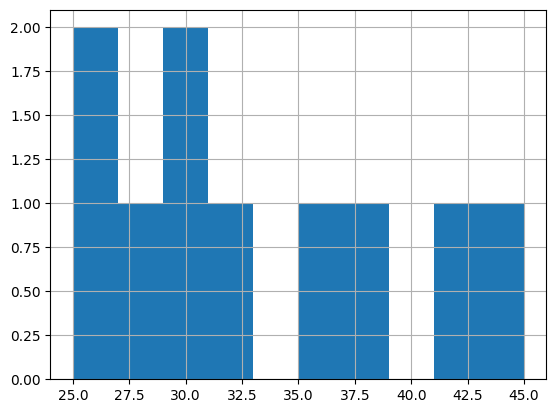

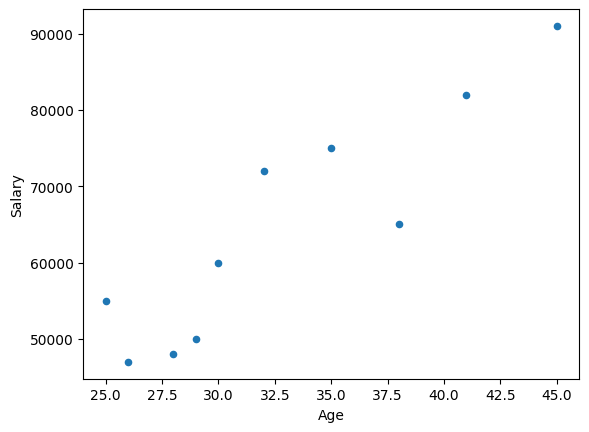

In [83]:
df['Age'].hist() 
df.plot(kind='scatter', x='Age', y='Salary')  # Creating a scatter plot of "Age" vs "Salary"

## Merge & Join Date
In pandas for merging and joining data, you can use the `merge()` function or the `join()` method. Here's a brief overview of how to use them:
- InnerJoin: Returns only the rows that have matching values in both DataFrames based on the specified key(s).
- LeftJoin: Returns all the rows from the left DataFrame and the matching rows from the right DataFrame. If there is no match, the result will contain NaN for the right DataFrame's columns.
- RightJoin: Returns all the rows from the right DataFrame and the matching rows from the left DataFrame. If there is no match, the result will contain NaN for the left DataFrame's columns.
- OuterJoin: Returns all the rows from both DataFrames, with NaN in place where there are no matches.
**Syntax for merge**
- pd.merge(left, right, how='inner', on=None, left_on=None, right_on=None, left_index=False, right_index=False, sort=True, suffixes=('_x', '_y'), copy=True, indicator=False, validate=None)
- pd.join(right, on=None, how='left', lsuffix='', rsuffix='', sort=False)

In [84]:
customer_df =pd.DataFrame({
    "CustomerID": [1, 2, 3, 4, 5],
    "Name": ["Alice", "Bob", "Charlie", "David", "Eva"],        
    "Age": [25, 30, 35, 40, 45]
})

order_df = pd.DataFrame({
    "OrderID": [101, 102, 103, 104, 105],
    "CustomerID": [1, 2, 1, 3, 4],
    "Amount": [250, 150, 300, 200, 400],
    "Date": ["2023-01-01", "2023-01-02", "2023-01-03", "2023-01-04", "2023-01-05"]
})


In [85]:
#Inner Join
inner_join_df = pd.merge(customer_df, order_df, on="CustomerID", how="inner")  # Performing an inner join on the "CustomerID" column
inner_join_df

#Left Join
left_join_df = pd.merge(customer_df, order_df, on="CustomerID", how="left")  # Performing a left join on the "CustomerID" column
left_join_df

#Right Join
right_join_df = pd.merge(customer_df, order_df, on="CustomerID", how="right")  # Performing a right join on the "CustomerID" column
right_join_df

#Outer Join
outer_join_df = pd.merge(customer_df, order_df, on="CustomerID", how="outer")  # Performing an outer join on the "CustomerID" column
outer_join_df   

,CustomerID,Name,Age,OrderID,Amount,Date
0,1,Alice,25,101.0,250.0,2023-01-01
1,1,Alice,25,103.0,300.0,2023-01-03
2,2,Bob,30,102.0,150.0,2023-01-02
3,3,Charlie,35,104.0,200.0,2023-01-04
4,4,David,40,105.0,400.0,2023-01-05
5,5,Eva,45,NaN,NaN,NaN


In [86]:
#Using the join() method to perform a join operation on two DataFrames based on their index
customer_df.set_index("CustomerID", inplace=True)  # Setting the "CustomerID" column as the index of the customer_df DataFrame
order_df.set_index("CustomerID", inplace=True)  # Setting the "CustomerID" column as the index of the order_df DataFrame
joined_df = customer_df.join(order_df, how="inner")  # Performing an inner join on the two DataFrames based on their index
joined_df.reset_index(inplace=True)  # Resetting the index of the joined DataFrame
joined_df

,CustomerID,Name,Age,OrderID,Amount,Date
0,1,Alice,25,101,250,2023-01-01
1,1,Alice,25,103,300,2023-01-03
2,2,Bob,30,102,150,2023-01-02
3,3,Charlie,35,104,200,2023-01-04
4,4,David,40,105,400,2023-01-05


## Concatenating two DataFrames vertically (stacking them on top of each other)
- Stacking two DataFrames vertically.
- Stacking two DataFrames vertically means combining them by adding the rows of one DataFrame below the rows of another DataFrame. This is useful when you have similar data in two separate DataFrames and want to combine them into a single DataFrame for analysis or further processing. The resulting DataFrame will have the same columns as the original DataFrames, and the rows will be stacked on top of each other.
- Stacking two DataFrames horizontally (side by side).
- Stacking two DataFrames horizontally means combining them by adding the columns of one DataFrame next to the columns of another DataFrame. This is useful when you have related data in two separate DataFrames and want to combine them into a single DataFrame for analysis or further processing. The resulting DataFrame will have the same number of rows as the original DataFrames, and the columns will be placed side by side.


In [87]:
# concatination
df1 = pd.DataFrame({
    "id": [1, 2, 3],
    "name": ["Alice", "Bob", "Charlie"]
})
df2 = pd.DataFrame({
    "id": [4, 5, 6],
    "name": ["David", "Eva", "Frank"]
})
df3 = pd.DataFrame({
    "id": [1,2,3],
    "age": [25, 30, 35]
})
concatenated_df = pd.concat([df1, df2], ignore_index=True)
concatenated_df

concatenated_df = pd.concat([df1, df3], axis=1)  # Concatenating the two DataFrames along columns (axis=1)
concatenated_df

,id,name,id,age
0,1,Alice,1,25
1,2,Bob,2,30
2,3,Charlie,3,35


In [88]:
df = pd.DataFrame({
    "id": [1, 2, 3, 4, 5],
    "name": ["Alice", "Bob", "Charlie", "David", "Eva"],    
    "age": [25, 30, 35, 40, 45],
    "gender": ["Female", "Male", "Male", "Male", "Female"],
    "country": ["USA", "Canada", "USA", "Canada", "USA"],
    "income": [50000, 60000, 70000, 80000, 90000]
})

In [90]:
df.groupby("country").agg(
    distinct_gender = ("gender", lambda x: list(set(x)))
).reset_index()  # Grouping the DataFrame by "country" and aggreg
    

,country,distinct_gender
0,Canada,[Male]
1,USA,"[Male, Female]"
